## Formal introduction to DataFrames

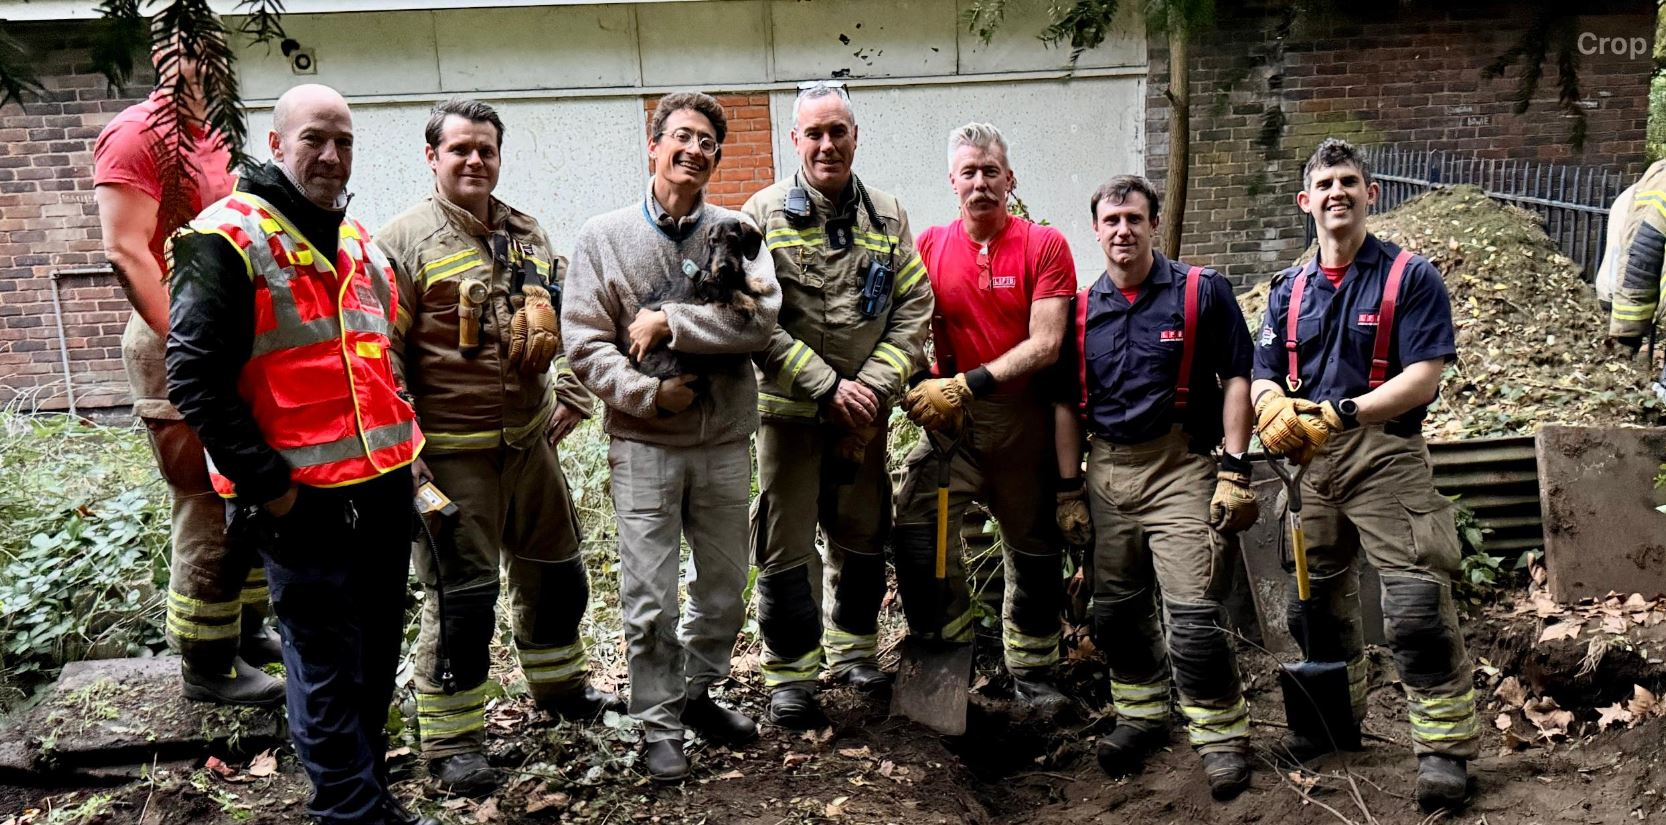

**0. The basics**

For homework, we took a deeper look into pandas, the Python Data Analysis Library. As we have seen, it contains an extremely powerful object called a DataFrame, designed to work with **tabular data.** Think about a Python implementation of a spreadsheet. Each row of the data frame refers to a different "unit of observation" and each column refers to a particular measurement or attribute of a unit.

**The London Fire Brigade**

<img src="images/lfb.png" width=500>

We have been using data collected by the London Fire Brigade. From [their website](https://data.london.gov.uk/dataset/animal-rescue-incidents-attended-by-lfb-2ogkn)...

The file has one row per incident (per rescue), and the columns describe aspects of what happened, the brigade resources involved, a time and a location.

**Loading the data**

If you didn't do this with your homework, you'll need to "install the app" `openpyxl` so that you can read the Excel file the brigade has made available.

In [ ]:
# Execute this install instruction (shift-return)

%pip install openpyxl

In [ ]:
import pandas as pd

# the string "url" contains the link from the LFB site.
url = "https://data.london.gov.uk/download/2ogkn/01007433-55c2-4b8a-b799-626d9e3bc284/Animal%20Rescue%20incidents%20attended%20by%20LFB%20from%20Jan%202009.csv.xlsx"

# To read in the data we have to look like someone with a browser and not someone with a Python program.
# So we are going to use a custom "User-Agent" in the header of our request for the file (more on this in class)
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

# the function "read_excel()" takes a few arguments... for example, we can tell Pandas that a column represents dates
lfb = pd.read_excel(url, parse_dates=["DateTimeOfCall"], storage_options=headers)

# recall the data's dimensions...
lfb.shape

In [ ]:
lfb.columns

Here is a description of the columns in the `lfb` DataFrame (often called a data dictionairy).

|variable                      |description |
|:-----------------------------|:-----------|
|IncidentNumber                | Unique incident ID |
|DateTimeOfCall                | Day and time of call (day/month/year hour:minute) |
|CalYear                       | Calendar Year |
|FinYear                       | Fiscal year|
|TypeOfIncident                | Type of incident |
|PumpCount                     | Pump count (number of trucks) |
|PumpHoursTotal                | Pump hours total |
|HourlyNotionalCost(£)         | Hourly cost |
|IncidentNotionalCost(£)       | Total cost of incident |
|FinalDescription              | Final description |
|AnimalGroupParent             | Type of animal |
|OriginofCall                  | Where call originated |
|PropertyType                  | Property type |
|PropertyCategory              | Property category |
|SpecialServiceTypeCategory.   | Service type category  |
|SpecialServiceType            | Service type |
|WardCode                      | Ward Code |
|Ward                          | Ward name |
|BoroughCode                   | Borough code |
|Borough                       | Borough name |
|StnGroundName.                | Station name |
|UPRN                          | Unique property reference number |
|Street                        | Street name |
|USRN                          | unique street reference number |
|PostcodeDistrict              | Postal code district |
|Easting_m                     | Easting measure |
|Northing_m                    | Northing measure |
|Easting_rounded               | Easting rounded |
|Northing_rounded              | Northing rounded |
|Latitude                      | Lat|
|Longitude                     | Long |

In [ ]:
# this sets a display option for data frames - usually you see just 10 columns and this way you see them all
pd.set_option("display.max_columns", None)

# have a look at the data
lfb.tail(5)

**1. Warm up**

There are various news stories about animal rescues. [Here's one.](https://www.london-fire.gov.uk/incidents/2025/october/dog-rescue-hackney/). Can we find the rescue in our data?

In [ ]:
# your code here

What about [this story](https://www.theguardian.com/world/2025/nov/02/firefighters-charities-animal-rescue-callouts-england) that includes overall statistics about domestic animals over time? Or [this one](https://www.telegraph.co.uk/news/2024/12/29/firefighters-spend-record-amount-money-rescuing-cats/?ICID=continue_without_subscribing_reg_first&icid=login_test-login_success-password#comment)...

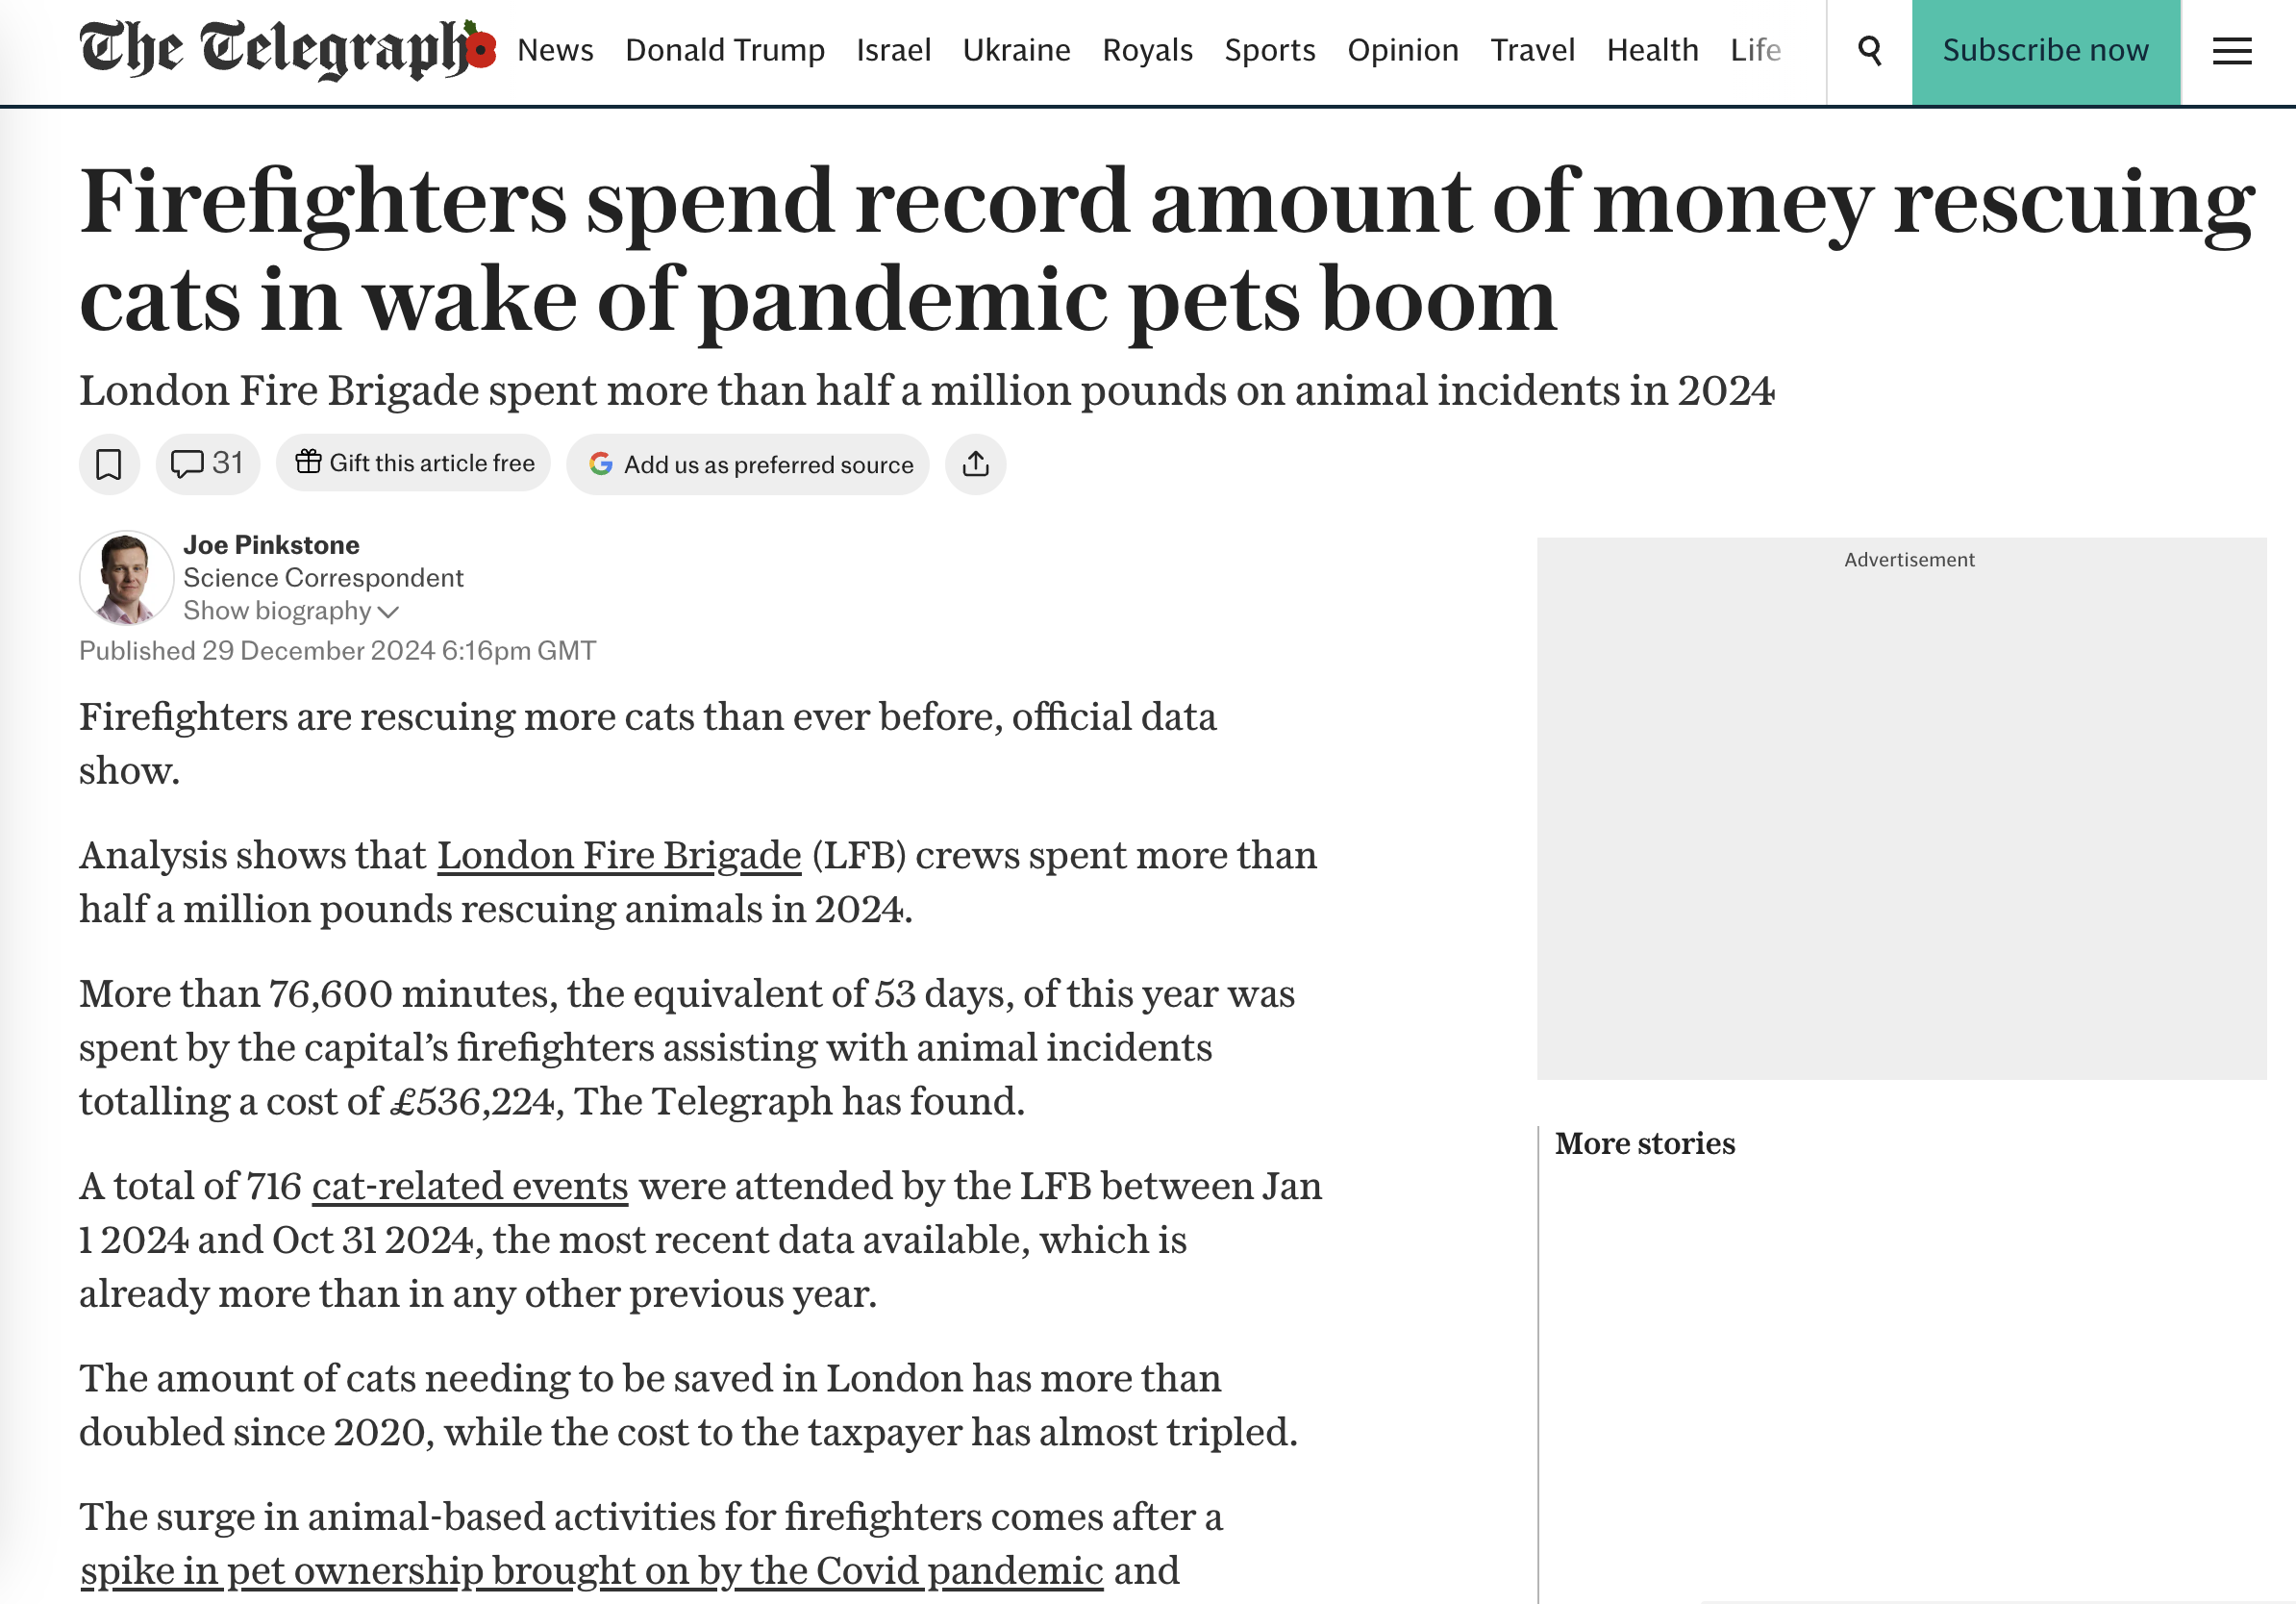

In [ ]:
# your code here


**2.** Let's consider the progression of rescues over time. Are they increasing? Decreasing? Come up with a hypothesis you'd like to explore and then map out what you might need to do to evaluate it.

In [ ]:
cat_mask = lfb["AnimalGroupParent"].str.strip().str.lower() == "cat"
cats = lfb[cat_mask]

cats_per_year = cats.groupby("CalYear").size().reset_index(name="Rescues")
cats_per_year

This cell draws a bar chart of the table above: one bar per calendar year, with the bar height showing the number of cat rescues.

In [ ]:
import altair as alt

alt.Chart(cats_per_year).mark_bar().encode(
    x=alt.X("CalYear:O", title="Calendar year"),
    y=alt.Y("Rescues:Q", title="Number of cat rescues"),
    tooltip=["CalYear", "Rescues"]
).properties(title="Cat rescues per year, London Fire Brigade", width=500, height=300)

This cell keeps only the cat and dog rows (ignoring upper/lower case), then counts rescues for each combination of year and animal. Both new charts below use this same table, so differences between them come from the display, not the data.

In [ ]:
animal_clean = lfb["AnimalGroupParent"].str.strip().str.lower()
cats_dogs = lfb[animal_clean.isin(["cat", "dog"])].copy()
cats_dogs["Animal"] = animal_clean[cats_dogs.index].str.capitalize()

cd_per_year = cats_dogs.groupby(["CalYear", "Animal"]).size().reset_index(name="Rescues")
cd_per_year

**Display 1: stacked bar chart.** One bar per year. Each bar is split into a cat part and a dog part stacked on top of each other, so the bar's total height is cats + dogs.

In [ ]:
alt.Chart(cd_per_year).mark_bar().encode(
    x=alt.X("CalYear:O", title="Calendar year"),
    y=alt.Y("Rescues:Q", title="Number of rescues"),
    color=alt.Color("Animal:N", title="Animal"),
    tooltip=["CalYear", "Animal", "Rescues"]
).properties(title="Cat and dog rescues per year (stacked), London Fire Brigade", width=500, height=300)

**Display 2: pyramid chart.** Years run down the side. Cat rescues extend to the left and dog rescues extend to the right. Both sides use the same scale (0 to 900), so bar lengths can be compared directly.

In [ ]:
cat_data = cd_per_year[cd_per_year["Animal"] == "Cat"]
dog_data = cd_per_year[cd_per_year["Animal"] == "Dog"]

# the same x range on both sides, so the bar lengths are comparable
same_range = [0, 900]

# cats on the left: the x scale is reversed so bars grow leftward
left = alt.Chart(cat_data).mark_bar(color="steelblue").encode(
    y=alt.Y("CalYear:O", title="Calendar year", axis=alt.Axis(orient="right")),
    x=alt.X("Rescues:Q", title="Cat rescues", scale=alt.Scale(domain=same_range, reverse=True)),
    tooltip=["CalYear", "Rescues"]
).properties(title="Cats", width=250, height=350)

# dogs on the right: year labels are hidden because the left chart already shows them
right = alt.Chart(dog_data).mark_bar(color="darkorange").encode(
    y=alt.Y("CalYear:O", title=None, axis=None),
    x=alt.X("Rescues:Q", title="Dog rescues", scale=alt.Scale(domain=same_range)),
    tooltip=["CalYear", "Rescues"]
).properties(title="Dogs", width=250, height=350)

alt.hconcat(left, right, spacing=0).properties(
    title="Cat and dog rescues per year (pyramid), London Fire Brigade"
)

**Inspiration Image**

![United_States_Population_Pyramid_(2024).png](https://upload.wikimedia.org/wikipedia/commons/1/11/United_States_Population_Pyramid_%282024%29.png?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=thumbnail_unscaled&_=20250530221050)

**Display 3: pyramid chart, modeled on the US population pyramid.** Like that chart, this one is a single plot with one shared axis. Cat counts are stored as negative numbers so their bars grow left from zero, and the axis labels show the absolute value, so no minus signs appear. Bars have black outlines, light vertical gridlines run behind them, the earliest year is at the bottom, and each side is labeled inside the plot.

In [ ]:
# make a copy of the table and flip the sign of the cat counts, so cats point left of zero
pyramid_data = cd_per_year.copy()
pyramid_data["Signed"] = pyramid_data["Rescues"]
pyramid_data.loc[pyramid_data["Animal"] == "Cat", "Signed"] = -pyramid_data["Rescues"]

# colors like the model: blue on the left, pink on the right
cat_color = "#1260e8"
dog_color = "#fcbcbc"

bars = alt.Chart(pyramid_data).mark_bar(stroke="black", strokeWidth=1).encode(
    y=alt.Y("CalYear:O", sort="descending", title="Calendar year"),
    x=alt.X(
        "Signed:Q",
        title="Rescues",
        scale=alt.Scale(domain=[-900, 900]),
        axis=alt.Axis(labelExpr="abs(datum.value)", grid=True, gridColor="#e6e6e6"),
        stack=None,
    ),
    color=alt.Color(
        "Animal:N",
        scale=alt.Scale(domain=["Cat", "Dog"], range=[cat_color, dog_color]),
        legend=None,
    ),
    tooltip=["CalYear", "Animal", "Rescues"],
)

# the "Cat" and "Dog" labels inside the plot, near the top
side_labels = pd.DataFrame({"x": [-700, 700], "label": ["Cat", "Dog"]})
labels = alt.Chart(side_labels).mark_text(fontSize=14).encode(
    x=alt.X("x:Q"),
    y=alt.value(12),
    text="label:N",
)

(bars + labels).properties(
    title="Cat and dog rescues per year, London Fire Brigade",
    width=600,
    height=400,
).configure_view(stroke=None)

In [ ]:
lfb.head()

In [ ]:
cats = lfb[lfb["AnimalGroupParent"].str.lower()=="cat"]
cats.groupby("CalYear")["IncidentNumber"].count()

In [ ]:
lfb.groupby("Borough")["IncidentNumber"].count()

This cell reads the borough boundaries from `data/london_boroughs.geojson` into a GeoDataFrame called `boroughs`. It has one row per borough, with a `name` column and a `geometry` column holding the borough's outline.

In [ ]:
import geopandas as gpd

boroughs = gpd.read_file("data/london_boroughs.geojson")
boroughs.head()

This cell counts the rescues (rows in `lfb`) for each borough and adds the count to `boroughs` as a new column called `Rescues`. The names in `lfb` are not consistently capitalized (some are "ENFIELD", some "Enfield"), so both sides are put in capitals just for the matching. Neither original name column is changed.

In [ ]:
# number of rescues for each borough name, with the names in capitals
rescue_counts = lfb["Borough"].str.upper().value_counts()

# look up each borough's count by its (capitalized) name
boroughs["Rescues"] = boroughs["name"].str.upper().map(rescue_counts)

boroughs[["name", "Rescues"]]

Check: every incident should be counted exactly once. So the sum of the `Rescues` column, plus the incidents whose borough is missing or not one of the 33 in `boroughs`, should equal the total number of rows in `lfb`. This cell also lists the unmatched names.

In [ ]:
in_boroughs = lfb["Borough"].str.upper().isin(boroughs["name"].str.upper())

print("rows in lfb:                  ", len(lfb))
print("sum of Rescues in boroughs:   ", boroughs["Rescues"].sum())
print("incidents with no borough match:", (~in_boroughs).sum())
print("sum + no match:               ", boroughs["Rescues"].sum() + (~in_boroughs).sum())

# which names did not match?
lfb.loc[~in_boroughs, "Borough"].value_counts(dropna=False)

The same choropleth map, drawn with Altair: each borough's outline is filled with a color based on its `Rescues` count, and hovering over a borough shows its name and count.

Altair needs a small fix to draw this file correctly: drawn directly from the GeoJSON's longitude/latitude, every borough was filled and the map came out as one solid block. So we first convert the outlines to the British National Grid (`to_crs(27700)`), which uses meters instead of degrees, and tell Altair to draw them as they are (`type="identity"`, with `reflectY=True` so north is up).

In [ ]:
# convert the outlines from longitude/latitude to the British National Grid (meters)
boroughs_bng = boroughs.to_crs(27700)

alt.Chart(boroughs_bng).mark_geoshape(stroke="black", strokeWidth=0.5).encode(
    color=alt.Color(
        "Rescues:Q",
        scale=alt.Scale(scheme="yelloworangered"),
        title="Number of rescues",
    ),
    tooltip=[alt.Tooltip("name:N", title="Borough"), alt.Tooltip("Rescues:Q", title="Rescues")],
).project(type="identity", reflectY=True).properties(
    title="Animal rescues by London borough, London Fire Brigade",
    width=600,
    height=500,
)

**Faceted map: cats, dogs, birds and horses.** This cell keeps only the rows for those four animals (ignoring capitalization) and counts rescues for each borough and animal. The table shows one row per borough and one column per animal.

In [ ]:
four_animals = ["cat", "dog", "bird", "horse"]

animal_lower = lfb["AnimalGroupParent"].str.strip().str.lower()
borough_upper = lfb["Borough"].str.upper()

four_rows = lfb[animal_lower.isin(four_animals)].copy()
four_rows["Animal"] = animal_lower[four_rows.index].str.capitalize()
four_rows["BoroughUpper"] = borough_upper[four_rows.index]

borough_animal = four_rows.groupby(["BoroughUpper", "Animal"]).size().reset_index(name="Rescues")

# one row per borough, one column per animal (0 where there were no rescues)
wide = borough_animal.pivot(index="BoroughUpper", columns="Animal", values="Rescues")
wide = wide.fillna(0).astype(int)
wide

This cell attaches those counts to the borough outlines. It makes one copy of every borough for each of the four animals (33 boroughs × 4 = 132 rows), then fills in the `Rescues` count for that borough and animal, using 0 where there were none. As before, the outlines are converted to the British National Grid so Altair draws them correctly. They are also simplified a little (to within 100 meters) so the chart stays small.

In [ ]:
shapes = boroughs[["name", "geometry"]].to_crs(27700)
shapes["geometry"] = shapes["geometry"].simplify(100)
shapes["BoroughUpper"] = shapes["name"].str.upper()

animal_names = pd.DataFrame({"Animal": ["Cat", "Dog", "Bird", "Horse"]})

# every borough paired with every animal
grid = shapes.merge(animal_names, how="cross")

# add the counts, and use 0 where a borough had no rescues of that animal
grid = grid.merge(borough_animal, on=["BoroughUpper", "Animal"], how="left")
grid["Rescues"] = grid["Rescues"].fillna(0).astype(int)

facet_data = gpd.GeoDataFrame(grid, geometry="geometry", crs=shapes.crs)
facet_data.shape

This cell draws four choropleth maps in a 2 × 2 grid, one for each animal. (Altair's built-in faceting drew empty maps with these outlines, so the code makes one map per animal in a loop and arranges them.) **Each map has its own color scale**, because horse rescues (at most 33 in a borough) would look almost blank next to cats (up to 355). So you can compare *where* each animal is rescued, but a color in one map does not mean the same count as that color in another. Check each legend, or hover over a borough to see its count.

In [ ]:
maps = []

for animal in ["Cat", "Dog", "Bird", "Horse"]:
    one_animal = facet_data[facet_data["Animal"] == animal]

    one_map = alt.Chart(one_animal).mark_geoshape(stroke="black", strokeWidth=0.5).encode(
        color=alt.Color(
            "Rescues:Q",
            scale=alt.Scale(scheme="yelloworangered"),
            title="Rescues",
        ),
        tooltip=[
            alt.Tooltip("name:N", title="Borough"),
            alt.Tooltip("Animal:N", title="Animal"),
            alt.Tooltip("Rescues:Q", title="Rescues"),
        ],
    ).project(type="identity", reflectY=True).properties(title=animal, width=300, height=250)

    maps.append(one_map)

alt.concat(*maps, columns=2).resolve_scale(color="independent").properties(
    title="Rescues by London borough, by animal, London Fire Brigade"
)

Check: for each animal, the counts on the map should add up to the number of rows for that animal in `lfb`, except for incidents with no borough or a borough outside the 33 on the map. This cell prints both totals and the difference.

In [ ]:
for animal in ["Cat", "Dog", "Bird", "Horse"]:
    on_map = facet_data.loc[facet_data["Animal"] == animal, "Rescues"].sum()
    in_lfb = (four_rows["Animal"] == animal).sum()
    print(animal, "| on map:", on_map, "| in lfb:", in_lfb, "| not on map:", in_lfb - on_map)

**Ohio Senate results: vote shift by county.** This cell reads the Ohio results file into Python. The county margins are stored under `voteShiftCounties` in the first (and only) race: one entry for each of Ohio's 88 counties, holding the current margin and the margin from an earlier race that the file compares against (the file doesn't say which race that is).

In [1]:
import json
import pandas as pd

with open("data/ohio-senate-results.json") as f:
    ohio = json.load(f)

# the county margins are in the first (only) race
county_margins = ohio["races"][0]["voteShiftCounties"]

print("counties:", len(county_margins))
county_margins[0]

counties: 88


{'name': 'Adams',
 'percentIn': 99,
 'margin': 44.68,
 'marginLeadingParty': 'rep',
 'marginPastRaces': [{'marginShift': 21.06,
   'margin': 65.74,
   'leadingParty': 'rep',
   'marginShiftParty': 'dem'}]}

Each margin in the file is given as a size plus the party that led (for example `44.68` and `"rep"`). In 8 counties the leading party changed between the two races, and a shift can't be found by subtracting sizes alone ("Republican +5" followed by "Democratic +3" is a shift of 8, not 2). So this cell first turns each margin into a single signed number: **positive means a Democratic lead, negative means a Republican lead**. It builds a table called `margins` with one row per county, holding the signed margin now and the signed margin from the earlier race.

In [2]:
rows = []

for county in county_margins:
    past = county["marginPastRaces"][0]

    # signed margin now: positive = Democratic lead, negative = Republican lead
    if county["marginLeadingParty"] == "dem":
        margin_now = county["margin"]
    else:
        margin_now = -county["margin"]

    # signed margin in the earlier race, same rule
    if past["leadingParty"] == "dem":
        margin_before = past["margin"]
    else:
        margin_before = -past["margin"]

    rows.append({"County": county["name"], "MarginNow": margin_now, "MarginBefore": margin_before})

margins = pd.DataFrame(rows)
margins.head(10)

,County,MarginNow,MarginBefore
0,Adams,-44.68,-65.74
1,Allen,-31.02,-44.10
2,Ashland,-34.38,-49.95
3,Ashtabula,-9.18,-28.38
4,Athens,30.46,10.73
5,Auglaize,-53.39,-64.56
6,Belmont,-26.29,-47.29
7,Brown,-42.80,-61.50
8,Butler,-10.32,-26.27
9,Carroll,-38.28,-54.73


This cell computes the shift: `change = margin now - margin before`, using the signed margins. A positive change means the county moved toward the Democrats, a negative change means it moved toward the Republicans, and the size of the shift is the change with its sign removed (in percentage points). The result is the table `shift` with one row per county and three columns: `County`, `ShiftToward` (which party gained) and `Size` (how many points).

In [3]:
change = margins["MarginNow"] - margins["MarginBefore"]

shift = pd.DataFrame({"County": margins["County"]})

# which party gained: positive change = Democratic, negative change = Republican
shift["ShiftToward"] = "Democratic"
shift.loc[change < 0, "ShiftToward"] = "Republican"
shift.loc[change == 0, "ShiftToward"] = "No change"

# how big the shift was, in percentage points
shift["Size"] = change.abs().round(2)

shift.head(10)

,County,ShiftToward,Size
0,Adams,Democratic,21.06
1,Allen,Democratic,13.08
2,Ashland,Democratic,15.57
3,Ashtabula,Democratic,19.20
4,Athens,Democratic,19.73
5,Auglaize,Democratic,11.17
6,Belmont,Democratic,21.00
7,Brown,Democratic,18.70
8,Butler,Democratic,15.95
9,Carroll,Democratic,16.45


Check: the file also lists its own shift for each county (`marginShift` and `marginShiftParty`). We never used those numbers above, so they are a separate answer to compare against. This cell lines the file's numbers up next to ours and counts the counties where the party or the size disagrees (the size is allowed to differ by up to 0.02, in case of rounding).

In [4]:
# the shift as the file reports it
file_rows = []

for county in county_margins:
    past = county["marginPastRaces"][0]
    file_rows.append({
        "County": county["name"],
        "FileToward": past["marginShiftParty"],
        "FileSize": past["marginShift"],
    })

file_shift = pd.DataFrame(file_rows)

# the file writes "dem" and "rep"; ours are spelled out
file_shift["FileToward"] = file_shift["FileToward"].replace({"dem": "Democratic", "rep": "Republican"})

check = shift.merge(file_shift, on="County")
check["SizeDifference"] = (check["Size"] - check["FileSize"]).abs()

party_disagree = check["ShiftToward"] != check["FileToward"]
size_disagree = check["SizeDifference"] > 0.02

print("counties compared:           ", len(check))
print("party disagrees:             ", party_disagree.sum())
print("size disagrees by more than 0.02:", size_disagree.sum())
print("largest size difference:     ", check["SizeDifference"].max().round(3))

# any county where we and the file disagree
check[party_disagree | size_disagree]

counties compared:            88
party disagrees:              0
size disagrees by more than 0.02: 0
largest size difference:      0.0


,County,ShiftToward,Size,FileToward,FileSize,SizeDifference


**Mapping the shift.** This cell reads the outlines of every US county from the zip file, keeps only Ohio (state code `39`, which gives 88 counties), and attaches our `shift` table by matching county names. The outlines are converted to a flat map projection (`EPSG:3857`, measured in meters) so Altair draws them correctly, as with the London maps. The result is `ohio_counties`.

In [5]:
import geopandas as gpd
import altair as alt

# read the county outlines for the whole US straight from the zip file
us_counties = gpd.read_file("zip://data/cb_2018_us_county_20m.zip")

# keep only Ohio (state code 39) and convert to a flat projection measured in meters
ohio_counties = us_counties[us_counties["STATEFP"] == "39"][["NAME", "geometry"]].to_crs(3857)

# attach the shift we computed, matching on the county name
ohio_counties = ohio_counties.merge(shift, left_on="NAME", right_on="County")

print("Ohio counties:", len(ohio_counties))
ohio_counties[["County", "ShiftToward", "Size"]].head()

Ohio counties: 88


,County,ShiftToward,Size
0,Summit,Democratic,15.60
1,Putnam,Democratic,9.47
2,Fulton,Democratic,14.23
3,Montgomery,Democratic,14.48
4,Wood,Democratic,14.74


Each arrow will sit at the middle of its county (the county's centroid). This cell makes a plain table called `arrows` with one row per county: the county, which party gained, the size of the shift, the `x` and `y` position of the arrow, and the `Angle` it points. Democratic arrows point up-left (`-45` degrees) and Republican arrows point up-right (`45` degrees), measured clockwise from straight up.

In [6]:
middle = ohio_counties.geometry.centroid

arrows = pd.DataFrame({
    "County": ohio_counties["County"],
    "ShiftToward": ohio_counties["ShiftToward"],
    "Size": ohio_counties["Size"],
    "x": middle.x,
    "y": middle.y,
})

# Democratic arrows point up-left, Republican arrows point up-right
arrows["Angle"] = arrows["ShiftToward"].map({"Democratic": -45, "Republican": 45})

arrows.head()

,County,ShiftToward,Size,x,y,Angle
0,Summit,Democratic,15.60,-9.076014e+06,5.030793e+06,-45
1,Putnam,Democratic,9.47,-9.365707e+06,5.015456e+06,-45
2,Fulton,Democratic,14.23,-9.364832e+06,5.101581e+06,-45
3,Montgomery,Democratic,14.48,-9.383174e+06,4.830283e+06,-45
4,Wood,Democratic,14.74,-9.308844e+06,5.065975e+06,-45


This cell draws the map in two layers: the county outlines underneath, and one arrow per county on top. Blue arrows point up-left for a shift toward the Democrats and red arrows point up-right for a shift toward the Republicans. The arrow's size shows the size of the shift, with the length of an arrow proportional to the shift, so an arrow for a 20-point shift is twice as long as one for a 10-point shift.

**Hover anywhere inside a county** (not just on its arrow) to see its name, which party the shift was toward, and the size of the shift in percentage points. This makes it easy to check any county against the `shift` table.

This follows the vote-shift map on NBC's Ohio Senate results page, which says the comparison is with the 2024 presidential election. Its statewide figure (16.06 points toward Democrats) is the same as the one in our file.

In [10]:
# what shows up when you hover: the same three items on the county and on its arrow
hover_text = [
    alt.Tooltip("County:N", title="County"),
    alt.Tooltip("ShiftToward:N", title="Shift toward"),
    alt.Tooltip("Size:Q", title="Shift (points)", format=".2f"),
]

# layer 1: the county outlines (hovering anywhere inside a county shows its numbers)
outlines = alt.Chart(ohio_counties).mark_geoshape(fill="white", stroke="#999999", strokeWidth=0.6).encode(
    tooltip=hover_text,
)

# layer 2: one arrow per county, placed at its middle
arrow_layer = alt.Chart(arrows).mark_point(shape="arrow", filled=True, opacity=1).encode(
    longitude="x:Q",
    latitude="y:Q",
    angle=alt.Angle("Angle:Q", scale=None),
    size=alt.Size(
        "Size:Q",
        scale=alt.Scale(type="pow", exponent=2, domain=[0, 25], range=[0, 700]),
        title="Shift (points)",
    ),
    color=alt.Color(
        "ShiftToward:N",
        scale=alt.Scale(domain=["Democratic", "Republican"], range=["#0071d0", "#CA262B"]),
        title="Shift toward",
    ),
    tooltip=hover_text,
)

alt.layer(outlines, arrow_layer).project(type="identity", reflectY=True).properties(
    title="Ohio Senate race: shift in margin by county, compared with the 2024 presidential election",
    width=500,
    height=500,
)

alt.LayerChart(...)

Check: the map should have exactly one arrow for each of the 88 counties, each arrow should sit inside its own county, and the arrow sizes should match the shift sizes the file itself reports (`file_shift`, from the earlier check). This cell tests each of those and counts the arrows for each party.

In [9]:
print("arrows:", len(arrows), "| unique counties:", arrows["County"].nunique())

# does each arrow sit inside its own county? (the points use the same projection as the outlines)
points = gpd.GeoSeries(gpd.points_from_xy(arrows["x"], arrows["y"]), index=arrows.index, crs=ohio_counties.crs)
inside = ohio_counties.geometry.contains(points)
print("arrows inside their own county:", inside.sum(), "of", len(arrows))

# do the arrow sizes match the shifts the file reports?
compare = arrows.merge(file_shift, on="County")
print("largest difference from the file's own size:", (compare["Size"] - compare["FileSize"]).abs().max())

arrows["ShiftToward"].value_counts()

arrows: 88 | unique counties: 88
arrows inside their own county: 88 of 88
largest difference from the file's own size: 0.0


ShiftToward
Democratic    88
Name: count, dtype: int64